# CLIP ViT-B/16 features + Attention MIL (whole video)

Notebook `02-r2plus1d_fullvideo.ipynb` used **R(2+1)D-18** (Kinetics-400) and **averaged** the features of all 16-frame
clips of a video into one vector. This notebook changes two things:

1. **Backbone:** the frozen image encoder of **CLIP ViT-B/16** (OpenAI, trained on 400M image–text pairs) instead of R(2+1)D-18.
2. **Head:** **Multiple Instance Learning** instead of mean pooling. An anomaly usually lasts a few seconds of a long video
   (e.g. 19 anomalous clips out of 2,800), so averaging dilutes it until the anomalous video looks almost like a normal one.
   Here each video is a **bag of clips** and only the video label is known: an anomaly video has at least one anomalous
   clip, a normal video has none. A **gated attention** head (Ilse et al., 2018) learns a weight for every clip, so the few
   clips that contain the event can decide the prediction. The weights also show **where** in the video the anomaly is.

The TRAIN/VAL split, class balancing and metrics are the same as in notebook 02, so the VAL numbers are directly comparable.

Why CLIP:
- **Semantics:** CLIP was trained on far more diverse data than Kinetics and recognises objects and scenes (fire, smoke,
  weapons, broken glass, people on the ground, crashed cars), which is often what separates an anomaly from a normal scene.
- **Resolution:** 224×224 input instead of 112×112. People in surveillance video are small.
- **Text:** images and text share one embedding space, so a **zero-shot** baseline (text prompts, no training) comes for free.

CLIP is an image model and has no notion of motion. Motion is added back by averaging the frames of each 16-frame clip and
by the temporal convolution of the MIL head.

Pipeline:
1. **Feature extraction (once):** frozen CLIP image encoder on **every frame** of every video. The 512-d frame embeddings
   (L2-normalised) are averaged over each 16-frame clip → one 512-d feature per clip, on the same 16-frame clips as notebook 02.
   Two views (centre crop and its mirror image) are computed from a single decode of the video.
2. **Zero-shot baseline:** text prompts only, no training.
3. **Part A:** attention-MIL head on the *same* TRAIN/VAL split as notebook 02 → directly comparable numbers.
4. **Part B:** 5-fold cross-validation over all labelled videos (TRAIN + VAL). With only 53 VAL videos one video is
   ~1.9 % accuracy, so the cross-validated accuracy (350 videos) is the number to trust.
5. TEST predictions (Part A model and the 5-fold ensemble), anomaly timelines, comparison with notebook 02.

**Weights:** on the first run `transformers` downloads `openai/clip-vit-base-patch16` (~600 MB) to
`~/.cache/huggingface`. To use a copy you downloaded yourself, set `CLIP_MODEL` to that folder.

## 1. Configuration — change paths here

In [2]:
import os

# ---------------- PATHS (edit these if you move the notebook / dataset) ----------------
DATASET_ROOT = "/home/haseebumer/content/data/UCF_Crimes_MINI"   # Videos/ + Anomaly_Detection_splits/
SPLITS_DIR   = os.path.join(DATASET_ROOT, "Anomaly_Detection_splits")
FEATS_DIR    = "./features_clip_vitb16"  # cached clip features: <view>/<category>/<video>.npy, (N_clips, 512) float16
RUNS_DIR     = "./runs_ucf_clipmil"
PREV_RUNS    = {"02 R(2+1)D mean pooling": "./runs_ucf_fullvideo"}   # for the comparison table (skipped if missing)

# ---------------- CLIP BACKBONE ----------------
CLIP_MODEL   = "openai/clip-vit-base-patch16"   # Hugging Face id (downloaded on first use) or a local folder

# ---------------- SPLITS ----------------
VAL_FRACTION = 0.15        # same stratified hold-out as notebook 02 (same seed) -> Part A is directly comparable
N_FOLDS      = 5           # Part B: cross-validation over all labelled videos (TRAIN + VAL)

# ---------------- FEATURE EXTRACTION (frozen CLIP ViT-B/16 image encoder) ----------------
# A video is cut into consecutive, non-overlapping 16-frame clips (last one padded), as in notebook 02. Every frame is
# embedded by CLIP and the frame embeddings of a clip are averaged -> one MIL instance per clip.
CLIP_LEN     = 16
FRAME_STRIDE = 1           # embed every FRAME_STRIDE-th frame of a clip (1 = every frame). 2 or 4 is 2x / 4x faster
                           # (frames 1/15 s apart are near-identical); must divide CLIP_LEN
IMG_SIZE     = 224         # CLIP input: short side resized to 224 (bicubic), centre crop 224x224
CLIPS_PER_SEGMENT = 32     # a video is decoded and sent to the GPU 32 clips (512 frames) at a time
FRAME_BATCH  = 256         # frames per CLIP forward pass (lower it if the GPU runs out of memory)
NUM_WORKERS  = 8           # CPU decode processes, 1 FFmpeg thread each
PREFETCH     = 2
VIEWS        = {"center": False, "center_flip": True}   # view name -> horizontal flip. Train: a random view per video
                                                        # per epoch (augmentation). Eval: logits averaged over all views.

# ---------------- ZERO-SHOT BASELINE (text prompts, no training) ----------------
ANOMALY_PROMPTS = [f"a CCTV image of {s}" for s in [
    "a person being abused", "police arresting a person", "a building on fire", "a person being assaulted",
    "a burglar breaking into a building", "an explosion", "people fighting", "a road accident", "an armed robbery",
    "a person shooting a gun", "a person shoplifting in a store", "a person stealing something", "vandalism"]]
NORMAL_PROMPTS = [f"a CCTV image of {s}" for s in [
    "people walking normally", "an empty street", "cars driving normally on a road", "people shopping in a store",
    "an empty room", "a quiet parking lot", "people standing and talking"]]
ZS_TOPK      = 8           # video score = mean anomaly probability of its 8 most anomalous clips (~4 s)

# ---------------- ATTENTION-MIL HEAD ----------------
HIDDEN       = 256         # clip embedding size after the temporal conv
ATTN_DIM     = 128         # size of the gated attention layer
DROPOUT      = 0.5
BATCH_VIDEOS = 8           # videos per optimizer step (videos have different lengths -> gradient accumulation)
EPOCHS       = 40
LR           = 3e-4
WEIGHT_DECAY = 1e-2

SEED = 42

assert CLIP_LEN % FRAME_STRIDE == 0, "FRAME_STRIDE must divide CLIP_LEN"
os.makedirs(RUNS_DIR, exist_ok=True)
assert os.path.isdir(DATASET_ROOT), f"DATASET_ROOT not found: {DATASET_ROOT}"
assert os.path.isdir(SPLITS_DIR), f"SPLITS_DIR not found: {SPLITS_DIR}"

## 2. Imports and GPU setup

In [3]:
import random, time, copy, warnings
import numpy as np
import pandas as pd
import cv2
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, Sampler
from transformers import CLIPModel, AutoTokenizer
import matplotlib.pyplot as plt
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, classification_report)
from sklearn.model_selection import train_test_split, StratifiedKFold
from tqdm.auto import tqdm


def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

seed_everything(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.backends.cudnn.benchmark = False                # the MIL head sees a different sequence length for every video;
                                                      # benchmark mode would re-tune the conv for each new length
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True
AMP_DTYPE = torch.bfloat16

print("torch", torch.__version__, "| device:", device)
if device.type == "cuda":
    free, total = torch.cuda.mem_get_info()
    print(torch.cuda.get_device_name(0), f"| free {free/2**30:.1f} GB / {total/2**30:.1f} GB")

/home/haseebumer/anaconda3/envs/ml_env/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


torch 2.14.1+cu130 | device: cuda
NVIDIA GeForce RTX 5080 | free 15.0 GB / 15.6 GB


## 3. Build the file lists (0 = NORMAL, 1 = ANOMALY; VAL is the same stratified hold-out as notebook 02; TEST has no labels)

In [4]:
CLASSES = ["NORMAL", "ANOMALY"]
VIDEOS_DIR = os.path.join(DATASET_ROOT, "Videos")

def category(path):
    """Folder name of the video, e.g. 'Robbery' or 'Training_Normal_Videos_Anomaly'."""
    return os.path.basename(os.path.dirname(path))

def read_split(fname, labelled=True):
    """labelled=False: label is -1 and is never used (TEST is treated like unseen real-world data)."""
    items = []
    for line in open(os.path.join(SPLITS_DIR, fname)):
        rel = line.strip()
        if not rel:
            continue
        path = os.path.join(VIDEOS_DIR, rel)
        assert os.path.isfile(path), f"missing video: {path}"
        items.append((path, (0 if "Normal" in category(path) else 1) if labelled else -1))
    return items


train_all = read_split("Anomaly_Train.txt")
test_items = read_split("Anomaly_Test.txt", labelled=False)
train_items, val_items = train_test_split(train_all, test_size=VAL_FRACTION, random_state=SEED,
                                          stratify=[category(p) for p, _ in train_all])
train_items, val_items = sorted(train_items), sorted(val_items)

# All labelled videos in one list: Part A uses TRAIN_IDX / VAL_IDX, Part B splits all of them into folds.
LAB_ITEMS = train_items + val_items
TRAIN_IDX = np.arange(len(train_items))
VAL_IDX   = np.arange(len(train_items), len(LAB_ITEMS))
Y_LAB     = torch.tensor([float(l) for _, l in LAB_ITEMS], device=device)

for name, it in [("TRAIN", train_items), ("VAL", val_items)]:
    labs = [l for _, l in it]
    print(f"{name:5s}: {len(it):5d} videos | anomaly {sum(labs):4d} | normal {len(labs)-sum(labs):4d}")
print(f"TEST : {len(test_items):5d} videos | unlabelled (predictions only)")

TRAIN:   297 videos | anomaly  165 | normal  132
VAL  :    53 videos | anomaly   29 | normal   24
TEST :    84 videos | unlabelled (predictions only)


## 4. Feature extraction — frozen CLIP ViT-B/16, every frame, cached to disk

- Same clips as notebook 02: consecutive non-overlapping 16-frame clips, the last clip padded by repeating the last frame.
- Each frame: short side resized to 224 (bicubic), centre crop 224×224, CLIP normalisation → CLIP image encoder →
  projected 512-d embedding (the image–text space), L2-normalised. The 16 frame embeddings of a clip are averaged into
  one 512-d clip feature.
- The backbone is **not** fine-tuned, so the features contain no information about our labels and can be reused for every
  fold of Part B.
- Each video is decoded **once**: the mirror view is made on the GPU from the same frames.
- Videos are streamed in segments of `CLIPS_PER_SEGMENT` clips. The clip features of a video are saved as
  `FEATS_DIR/<view>/<category>/<video>.npy` (float16).
- Extraction is **resumable**: videos whose `.npy` files already exist are skipped, so this cell is fast after the first run.
- The text embeddings of the zero-shot prompts are computed in the same cell and saved to `FEATS_DIR/text_embeddings.pt`.

Cost: ~3.2M frames × 2 views through ViT-B/16, about **1 h** on the RTX 5080 (measured ~800 frames/s). Set
`FRAME_STRIDE = 4` in section 1 to embed every 4th frame instead: about **15 min**, with almost identical clip features.

In [5]:
def open_video(path):
    # 1 decode thread per video: the default (16) costs ~5x more RAM per open video and,
    # summed over all workers, oversubscribes the CPU.
    return cv2.VideoCapture(path, cv2.CAP_FFMPEG, [cv2.CAP_PROP_N_THREADS, 1])


def frame_count(path):
    cap = open_video(path)
    n = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    cap.release()
    return n


def video_fps(path):
    cap = open_video(path)
    fps = cap.get(cv2.CAP_PROP_FPS)
    cap.release()
    return fps if fps and fps > 0 else 30.0


SEG_FRAMES = CLIP_LEN * CLIPS_PER_SEGMENT
FRAMES_PER_CLIP = CLIP_LEN // FRAME_STRIDE       # frames embedded per clip


def resize_crop(fr):
    """BGR frame -> uint8 (IMG_SIZE, IMG_SIZE, 3) RGB: short side resized to IMG_SIZE (bicubic, as CLIP), centre crop."""
    h, w = fr.shape[:2]
    s = IMG_SIZE / min(h, w)
    nh, nw = max(IMG_SIZE, round(h * s)), max(IMG_SIZE, round(w * s))
    fr = cv2.resize(fr, (nw, nh), interpolation=cv2.INTER_CUBIC)
    y, x = (nh - IMG_SIZE) // 2, (nw - IMG_SIZE) // 2
    return cv2.cvtColor(fr[y:y + IMG_SIZE, x:x + IMG_SIZE], cv2.COLOR_BGR2RGB)


def read_frames(path, start, count):
    """Decodes `count` consecutive frames from frame `start` (count=None: up to the end of the video) and keeps every
       FRAME_STRIDE-th one (`start` is a multiple of CLIP_LEN, so the kept frames line up with the clips).
       Returns (list of uint8 (IMG_SIZE, IMG_SIZE, 3) RGB arrays, number of frames decoded)."""
    cap = open_video(path)
    if start > 0:
        cap.set(cv2.CAP_PROP_POS_FRAMES, start)

    def grab():
        frames, n = [], 0
        while count is None or n < count:
            if not cap.grab():
                break
            if n % FRAME_STRIDE == 0:                 # skipped frames are only grabbed, never converted
                ok, fr = cap.retrieve()
                if not ok:
                    break
                frames.append(resize_crop(fr))
            n += 1
        return frames, n

    frames, n = grab()
    if n == 0 and start > 0:                # seek failed -> reopen and step through the frames before `start`
        cap.release(); cap = open_video(path)
        for _ in range(start):
            if not cap.grab():
                break
        frames, n = grab()
    cap.release()
    return frames, n


class SegmentDataset(Dataset):
    """One item = one segment of one video: up to CLIPS_PER_SEGMENT consecutive 16-frame clips, returned as
       (n_clips * FRAMES_PER_CLIP, H, W, 3) uint8 frames in time order. The segments of a video together cover every
       one of its frames. Keys (vid, seg) come from SegmentSampler."""
    def __init__(self, items):
        self.items = items
        self.n_frames = [frame_count(p) for p, _ in items]
        self.n_segs = [max(1, -(-n // SEG_FRAMES)) for n in self.n_frames]

    def __len__(self):
        return sum(self.n_segs)

    def __getitem__(self, key):
        vid, seg = key
        path = self.items[vid][0]
        last = seg == self.n_segs[vid] - 1
        frames, n_read = read_frames(path, seg * SEG_FRAMES, None if last else SEG_FRAMES)   # last: read to the end
        if not frames and seg == 0:
            print(f"WARNING: could not decode {path}")
            frames, n_read = [np.zeros((IMG_SIZE, IMG_SIZE, 3), np.uint8)], 1
        n_clips = -(-n_read // CLIP_LEN)
        if frames:
            frames += [frames[-1]] * (n_clips * FRAMES_PER_CLIP - len(frames))   # pad the last clip
        x = np.stack(frames) if frames else np.zeros((0, IMG_SIZE, IMG_SIZE, 3), np.uint8)
        return torch.from_numpy(x), n_clips, vid, last


class SegmentSampler(Sampler):
    """Yields the segments of video 0, then video 1, ... in order (the DataLoader keeps this order with many workers)."""
    def __init__(self, ds):
        self.ds = ds

    def __len__(self):
        return sum(self.ds.n_segs)

    def __iter__(self):
        for v in range(len(self.ds.items)):
            for s in range(self.ds.n_segs[v]):
                yield (v, s)


def worker_init(_):
    cv2.setNumThreads(1)                     # one decode thread per worker; parallelism comes from workers


CLIP_MEAN = torch.tensor([0.48145466, 0.4578275, 0.40821073], device=device).view(1, 3, 1, 1)   # CLIP stats
CLIP_STD  = torch.tensor([0.26862954, 0.26130258, 0.27577711], device=device).view(1, 3, 1, 1)


@torch.no_grad()
def embed_frames(clip, x):
    """(F, H, W, 3) uint8 frames -> {view: (F, 512) L2-normalised CLIP image embeddings}."""
    x = x.to(device, non_blocking=True).permute(0, 3, 1, 2).float().div_(255)
    x = (x - CLIP_MEAN) / CLIP_STD
    out = {view: [] for view in VIEWS}
    for b in range(0, len(x), FRAME_BATCH):
        xb = x[b:b + FRAME_BATCH]
        for view, flip in VIEWS.items():
            with torch.autocast("cuda", dtype=AMP_DTYPE):
                e = clip.visual_projection(clip.vision_model(pixel_values=xb.flip(-1) if flip else xb).pooler_output)
            out[view].append(F.normalize(e.float(), dim=-1))
    return {view: torch.cat(e) for view, e in out.items()}


@torch.no_grad()
def embed_text(clip, tokenizer, prompts):
    tok = tokenizer(prompts, padding=True, return_tensors="pt").to(device)
    e = clip.text_projection(clip.text_model(input_ids=tok["input_ids"], attention_mask=tok["attention_mask"]).pooler_output)
    return F.normalize(e.float(), dim=-1)


def feat_path(path, view):
    rel = os.path.relpath(path, VIDEOS_DIR)
    return os.path.join(FEATS_DIR, view, os.path.splitext(rel)[0] + ".npy")


@torch.no_grad()
def extract_features(clip, items):
    """Saves the (N_clips, 512) float16 clip features of every view of every video in `items` that is not cached yet."""
    todo = [it for it in items if not all(os.path.exists(feat_path(it[0], v)) for v in VIEWS)]
    print(f"{len(items) - len(todo)} videos cached, {len(todo)} to extract")
    if not todo:
        return
    ds = SegmentDataset(todo)
    print(f"{sum(ds.n_frames):,} frames to decode")
    loader = DataLoader(ds, sampler=SegmentSampler(ds), batch_size=None, num_workers=NUM_WORKERS,
                        pin_memory=True, worker_init_fn=worker_init,
                        prefetch_factor=PREFETCH if NUM_WORKERS > 0 else None)
    chunks = {view: [] for view in VIEWS}
    for x, n_clips, vid, last in tqdm(loader, desc="extract"):
        if n_clips:
            for view, e in embed_frames(clip, x).items():
                chunks[view].append(e.view(n_clips, FRAMES_PER_CLIP, -1).mean(1).cpu())   # frame mean per clip
        if last:
            for view in VIEWS:
                out = feat_path(todo[vid][0], view)
                os.makedirs(os.path.dirname(out), exist_ok=True)
                np.save(out[:-4] + ".tmp.npy", torch.cat(chunks[view]).half().numpy())
                os.replace(out[:-4] + ".tmp.npy", out)            # atomic: an interrupted run never leaves a broken file
            chunks = {view: [] for view in VIEWS}


clip = CLIPModel.from_pretrained(CLIP_MODEL, attn_implementation="sdpa").to(device).eval()
tokenizer = AutoTokenizer.from_pretrained(CLIP_MODEL)
print(f"CLIP image encoder: {sum(p.numel() for p in clip.vision_model.parameters()) / 1e6:.1f}M params, "
      f"embedding dim {clip.config.projection_dim}")

os.makedirs(FEATS_DIR, exist_ok=True)
torch.save({"anomaly": embed_text(clip, tokenizer, ANOMALY_PROMPTS).cpu(),
            "normal": embed_text(clip, tokenizer, NORMAL_PROMPTS).cpu(),
            "logit_scale": clip.logit_scale.exp().item()}, os.path.join(FEATS_DIR, "text_embeddings.pt"))

t0 = time.time()
extract_features(clip, LAB_ITEMS + test_items)
print(f"feature extraction done in {(time.time() - t0) / 60:.1f} min")
del clip
torch.cuda.empty_cache()

Loading weights: 100%|██████████| 398/398 [00:00<00:00, 70447.88it/s]


CLIP image encoder: 85.8M params, embedding dim 512
434 videos cached, 0 to extract
feature extraction done in 0.0 min


### Load the cached features onto the GPU (float16)

In [6]:
def load_feats(items):
    """{view: [ (N_clips, 512) float16 tensor on the GPU, one per video ]}"""
    return {view: [torch.from_numpy(np.load(feat_path(p, view))).to(device) for p, _ in items] for view in VIEWS}


F_LAB  = load_feats(LAB_ITEMS)
F_TEST = load_feats(test_items)
D_FEAT = F_LAB["center"][0].shape[1]

for name, feats in [("TRAIN", [F_LAB["center"][i] for i in TRAIN_IDX]), ("VAL", [F_LAB["center"][i] for i in VAL_IDX]),
                    ("TEST", F_TEST["center"])]:
    n = np.array([len(f) for f in feats])
    print(f"{name:5s}: {n.sum():6d} clips | clips/video min {n.min()} median {int(np.median(n))} max {n.max()}")

TRAIN: 149747 clips | clips/video min 13 median 140 max 39252
VAL  :  26299 clips | clips/video min 21 median 170 max 7910
TEST :  22643 clips | clips/video min 14 median 105 max 6750


## 5. Plotting and metric helpers

In [7]:
def plot_history(hist, title, best_ep=None, save_name=None):
    """hist values may be lists (one run) or arrays of shape (folds, epochs) (mean ± std is drawn)."""
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    for ax, key, name in [(axes[0], "loss", "Loss"), (axes[1], "acc", "Accuracy"), (axes[2], "auc", "ROC-AUC")]:
        for split, marker in [("train", "o-"), ("val", "s-")]:
            if f"{split}_{key}" not in hist:
                continue
            v = np.atleast_2d(np.array(hist[f"{split}_{key}"]))
            ep = np.arange(1, v.shape[1] + 1)
            m, s = v.mean(0), v.std(0)
            ax.plot(ep, m, marker, ms=3, label=f"{split.capitalize()} {name.lower()}")
            if len(v) > 1:
                ax.fill_between(ep, m - s, m + s, alpha=0.2)
        if best_ep:
            ax.axvline(best_ep, color="red", ls="--", lw=1.5, label=f"Selected epoch ({best_ep})")
        ax.set_xlabel("Epoch"); ax.set_ylabel(name); ax.set_title(f"{title} — {name}")
        ax.grid(alpha=0.3); ax.legend()
    plt.tight_layout()
    if save_name:
        plt.savefig(os.path.join(RUNS_DIR, save_name), dpi=150)
    plt.show()


def sigmoid(z):
    return 1 / (1 + np.exp(-np.asarray(z, np.float64)))


def metric_dict(y, probs):
    pred = (probs >= 0.5).astype(int)
    return {"accuracy": accuracy_score(y, pred),
            "precision": precision_score(y, pred, zero_division=0),
            "recall": recall_score(y, pred, zero_division=0),
            "f1": f1_score(y, pred, zero_division=0),
            "roc_auc": roc_auc_score(y, probs) if len(set(y)) == 2 else float("nan")}


def item_metrics(probs, items):
    return metric_dict(np.array([l for _, l in items]), probs)


def report(probs, items, split_name, stage_name, train_m=None, train_name="TRAIN"):
    """train_m: metrics on the training videos, shown as an extra row of the table (the classification report,
       per-category accuracy and confusion matrix are for `items` only)."""
    y = np.array([l for _, l in items])
    pred = (probs >= 0.5).astype(int)
    m = metric_dict(y, probs)
    print(f"===== {stage_name} | {split_name} ({len(items)} videos, every frame) =====")
    rows = ([train_m] if train_m else []) + [m]
    print(pd.DataFrame(rows, index=([train_name] if train_m else []) + [split_name]).round(4).to_string())
    print(classification_report(y, pred, target_names=CLASSES, digits=4, zero_division=0))

    df = pd.DataFrame({"video": [os.path.relpath(p, VIDEOS_DIR) for p, _ in items],
                       "category": [category(p) for p, _ in items],
                       "label": np.array(CLASSES)[y], "anomaly_prob": probs.round(4),
                       "prediction": np.array(CLASSES)[pred]})
    df["correct"] = df["label"] == df["prediction"]
    print("Per-category accuracy:")
    print(df.groupby("category")["correct"].agg(["mean", "size"]).rename(columns={"mean": "acc", "size": "videos"})
            .round(3).to_string(), "\n")

    cm = confusion_matrix(y, pred, labels=[0, 1])
    fig, ax = plt.subplots(figsize=(4.5, 4))
    ax.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=13,
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xticks([0, 1], CLASSES); ax.set_yticks([0, 1], CLASSES)
    ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title(f"{stage_name} — {split_name}")
    plt.tight_layout(); plt.show()
    return m

## 6. Zero-shot baseline — CLIP + text prompts, no training

Each clip feature is compared with the text embeddings of the anomaly prompts (one per UCF-Crime category) and the normal
prompts. A softmax over all prompts gives a per-clip anomaly probability (the sum over the anomaly prompts). The video
score is the mean of its `ZS_TOPK` most anomalous clips, averaged over both views.

Without training the score is not calibrated, so 0.5 is not a meaningful threshold. The threshold is the one with the
best accuracy on the **TRAIN** videos, and is then applied to VAL. ROC-AUC does not depend on the threshold.
This shows how much CLIP already "knows" before any training.

zero-shot threshold (best TRAIN accuracy): 0.8703 | TRAIN acc 0.7643 | TRAIN auc 0.8211
===== CLIP zero-shot | VAL (53 videos, every frame) =====
       accuracy  precision  recall      f1  roc_auc
TRAIN    0.7643     0.7684  0.8242  0.7953   0.8211
VAL      0.8302     0.8571  0.8276  0.8421   0.8261
              precision    recall  f1-score   support

      NORMAL     0.8000    0.8333    0.8163        24
     ANOMALY     0.8571    0.8276    0.8421        29

    accuracy                         0.8302        53
   macro avg     0.8286    0.8305    0.8292        53
weighted avg     0.8313    0.8302    0.8304        53

Per-category accuracy:
                                  acc  videos
category                                     
Abuse                           1.000       2
Arrest                          1.000       1
Arson                           1.000       1
Assault                         1.000       2
Burglary                        0.667       3
Explosion                 

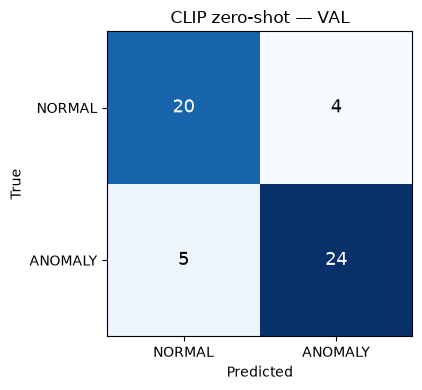

In [8]:
TEXT = torch.load(os.path.join(FEATS_DIR, "text_embeddings.pt"))
TEXT_ALL = torch.cat([TEXT["anomaly"], TEXT["normal"]]).to(device)   # anomaly prompts first
N_ANOM_PROMPTS = len(TEXT["anomaly"])


def zs_clip_probs(x):
    """(N_clips, 512) clip features -> (N_clips,) zero-shot anomaly probability of every clip."""
    logits = TEXT["logit_scale"] * F.normalize(x.float(), dim=-1) @ TEXT_ALL.T
    return logits.softmax(-1)[:, :N_ANOM_PROMPTS].sum(-1)


@torch.no_grad()
def zs_video_scores(feats, idx):
    out = []
    for i in idx:
        p = torch.stack([zs_clip_probs(feats[v][i]) for v in VIEWS]).mean(0)
        out.append(p.topk(min(ZS_TOPK, len(p))).values.mean().item())
    return np.array(out)


def prob_to_logit(p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p))


zs_train, zs_val = zs_video_scores(F_LAB, TRAIN_IDX), zs_video_scores(F_LAB, VAL_IDX)
y_train = Y_LAB[TRAIN_IDX].cpu().numpy().astype(int)
cands = np.unique(zs_train)
zs_thr = cands[np.argmax([((zs_train >= t) == y_train).mean() for t in cands])]
print(f"zero-shot threshold (best TRAIN accuracy): {zs_thr:.4f} | TRAIN acc {((zs_train >= zs_thr) == y_train).mean():.4f} "
      f"| TRAIN auc {roc_auc_score(y_train, zs_train):.4f}")

metrics = {}
# shift so the TRAIN threshold maps to 0.5 (a monotone transform: ROC-AUC is unchanged)
metrics[("CLIP zero-shot", "TRAIN")] = item_metrics(sigmoid(prob_to_logit(zs_train) - prob_to_logit(zs_thr)), train_items)
metrics[("CLIP zero-shot", "VAL")] = report(sigmoid(prob_to_logit(zs_val) - prob_to_logit(zs_thr)), val_items, "VAL",
                                            "CLIP zero-shot", train_m=metrics[("CLIP zero-shot", "TRAIN")])

## 7. Model: gated attention MIL over the clip features of a video

For a video with clip features $x_1 \dots x_N$:
1. **Temporal conv** (kernel 3): $h_i$ mixes each clip with its neighbours. An event spans several 16-frame clips, and
   CLIP features carry no motion, so this is where short-range temporal context comes from.
2. **Gated attention**: $a_i = \mathrm{softmax}_i\big(w^\top(\tanh(V h_i) \odot \sigma(U h_i))\big)$, with $\sum_i a_i = 1$.
3. **Video logit** = $\mathrm{classifier}\big(\sum_i a_i h_i\big)$ = $\sum_i a_i \cdot \mathrm{classifier}(h_i)$, an
   attention-weighted average of **per-clip anomaly logits**. Mean pooling (notebook 02) is the special case $a_i = 1/N$.
   Here the model can put almost all the weight on the few clips that contain the event.

The loss is one BCE per video, because only video labels exist.

In [9]:
class AttentionMIL(nn.Module):
    """Gated attention MIL (Ilse et al., 2018) with a temporal conv in front.
       Input: (N_clips, d_in) features of one video.
       Output: video logit (1,), attention weights (N_clips,) summing to 1, per-clip anomaly logits (N_clips,)."""
    def __init__(self, d_in=D_FEAT, hidden=HIDDEN, attn_dim=ATTN_DIM, p_drop=DROPOUT):
        super().__init__()
        self.norm = nn.LayerNorm(d_in)
        self.embed = nn.Sequential(nn.Conv1d(d_in, hidden, kernel_size=3, padding=1), nn.GELU(), nn.Dropout(p_drop))
        self.attn_v = nn.Linear(hidden, attn_dim)
        self.attn_u = nn.Linear(hidden, attn_dim)
        self.attn_w = nn.Linear(attn_dim, 1)
        self.classifier = nn.Linear(hidden, 1)

    def forward(self, x):
        h = self.embed(self.norm(x.float()).T[None])[0].T                    # (N, hidden)
        a = self.attn_w(torch.tanh(self.attn_v(h)) * torch.sigmoid(self.attn_u(h))).squeeze(1)
        a = torch.softmax(a, dim=0)                                         # (N,)
        return self.classifier(a @ h), a, self.classifier(h).squeeze(1)


def make_criterion(idx):
    """BCE with pos_weight = #normal / #anomaly of the training videos `idx` (same balancing as notebook 02)."""
    n_pos = Y_LAB[idx].sum()
    return nn.BCEWithLogitsLoss(pos_weight=((len(idx) - n_pos) / n_pos).view(1))


def video_logits(model, feats, idx):
    """One logit per video: the model's video logit averaged over all views (test-time augmentation)."""
    return torch.cat([torch.stack([model(feats[v][i])[0] for v in VIEWS]).mean(0) for i in idx])


def train_epoch(model, optimizer, crit, idx):
    """One pass over the training videos in random order, one random view per video, BATCH_VIDEOS videos per step."""
    model.train()
    optimizer.zero_grad(set_to_none=True)
    order = np.random.permutation(idx)
    losses, correct = [], 0
    for n, i in enumerate(order, 1):
        logit = model(F_LAB[random.choice(list(VIEWS))][i])[0]
        loss = crit(logit, Y_LAB[i:i + 1])
        (loss / BATCH_VIDEOS).backward()
        losses.append(loss.item())
        correct += int((logit.item() > 0) == bool(Y_LAB[i]))
        if n % BATCH_VIDEOS == 0 or n == len(order):
            optimizer.step()
            optimizer.zero_grad(set_to_none=True)
    return float(np.mean(losses)), correct / len(order)


@torch.no_grad()
def evaluate(model, crit, idx):
    """loss, accuracy, ROC-AUC and logits on the labelled videos `idx` (all views averaged, no dropout)."""
    model.eval()
    logits = video_logits(model, F_LAB, idx)
    y = Y_LAB[idx]
    acc = ((logits > 0).float() == y).float().mean().item()
    return crit(logits, y).item(), acc, roc_auc_score(y.cpu().numpy(), logits.cpu().numpy()), logits.cpu().numpy()


def fit(train_idx, val_idx, epochs=EPOCHS, select_best=False, seed=SEED, verbose=True):
    """Trains a new AttentionMIL head on `train_idx`, evaluating on `val_idx` after every epoch.
       select_best=True: returns the weights of the epoch with the lowest val loss (smoother than accuracy on 53 videos).
       select_best=False: returns the last epoch (used for cross-validation, where no fold looks at its own val set)."""
    seed_everything(seed)
    model = AttentionMIL().to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    crit = make_criterion(train_idx)
    hist = {k: [] for k in ["train_loss", "train_acc", "val_loss", "val_acc", "val_auc"]}
    best_loss, best_state, best_ep = float("inf"), None, 0
    for ep in range(1, epochs + 1):
        t0 = time.time()
        tr_loss, tr_acc = train_epoch(model, optimizer, crit, train_idx)
        scheduler.step()
        va_loss, va_acc, va_auc, _ = evaluate(model, crit, val_idx)
        for k, v in zip(hist, [tr_loss, tr_acc, va_loss, va_acc, va_auc]):
            hist[k].append(v)
        flag = ""
        if select_best and va_loss < best_loss:
            best_loss, best_state, best_ep = va_loss, copy.deepcopy(model.state_dict()), ep
            flag = "  <- best"
        if verbose:
            print(f"epoch {ep:2d}/{epochs} | train loss {tr_loss:.4f} acc {tr_acc:.4f} | "
                  f"val loss {va_loss:.4f} acc {va_acc:.4f} auc {va_auc:.4f} | {time.time()-t0:.1f}s{flag}")
    if select_best:
        model.load_state_dict(best_state)
        if verbose:
            print(f"Loaded best epoch {best_ep} (val loss {best_loss:.4f})")
    model.eval()
    return model, hist, best_ep


@torch.no_grad()
def predict_test(models, stage_name, file_tag):
    """Anomaly probability of every TEST video: sigmoid of the video logit averaged over views and over `models`."""
    logits = np.mean([video_logits(m.eval(), F_TEST, range(len(test_items))).cpu().numpy() for m in models], axis=0)
    probs = sigmoid(logits)
    df = pd.DataFrame({"video": [os.path.relpath(p, VIDEOS_DIR) for p, _ in test_items],
                       "anomaly_prob": probs.round(4),
                       "prediction": np.where(probs >= 0.5, CLASSES[1], CLASSES[0])})
    out = os.path.join(RUNS_DIR, f"test_predictions_{file_tag}.csv")
    df.to_csv(out, index=False)
    print(f"===== {stage_name} | TEST ({len(df)} videos) -> {out} =====")
    print(df["prediction"].value_counts().to_string())
    return df


print("trainable params:", sum(p.numel() for p in AttentionMIL().parameters()))

trainable params: 460674


## 8. Part A — CLIP + Attention MIL on the same TRAIN / VAL split as notebook 02

Trains in seconds per epoch because the CLIP features are cached. The epoch with the lowest VAL loss is kept
(notebook 02 kept the epoch with the highest VAL accuracy; the loss is smoother on 53 videos).

In [10]:
model_a, hist_a, best_ep_a = fit(TRAIN_IDX, VAL_IDX, select_best=True)
torch.save({"model": model_a.state_dict(), "epoch": best_ep_a}, os.path.join(RUNS_DIR, "clipmil_best.pt"))

epoch  1/40 | train loss 0.3804 acc 0.8384 | val loss 0.2842 acc 0.8679 auc 0.9540 | 0.7s  <- best
epoch  2/40 | train loss 0.2204 acc 0.9057 | val loss 0.2608 acc 0.8679 auc 0.9641 | 0.2s  <- best
epoch  3/40 | train loss 0.1595 acc 0.9192 | val loss 0.2455 acc 0.8868 auc 0.9598 | 0.2s  <- best
epoch  4/40 | train loss 0.1068 acc 0.9663 | val loss 0.2211 acc 0.9245 auc 0.9655 | 0.2s  <- best
epoch  5/40 | train loss 0.0892 acc 0.9697 | val loss 0.2413 acc 0.9057 auc 0.9626 | 0.2s
epoch  6/40 | train loss 0.0589 acc 0.9798 | val loss 0.2473 acc 0.8868 auc 0.9641 | 0.2s
epoch  7/40 | train loss 0.0613 acc 0.9731 | val loss 0.2670 acc 0.9057 auc 0.9684 | 0.2s
epoch  8/40 | train loss 0.0374 acc 0.9933 | val loss 0.3555 acc 0.9057 auc 0.9569 | 0.2s
epoch  9/40 | train loss 0.0700 acc 0.9731 | val loss 0.3047 acc 0.8868 auc 0.9670 | 0.2s
epoch 10/40 | train loss 0.0512 acc 0.9798 | val loss 0.3644 acc 0.9057 auc 0.9655 | 0.2s
epoch 11/40 | train loss 0.0293 acc 0.9933 | val loss 0.2513 acc

### Part A — accuracy, loss & ROC-AUC curves

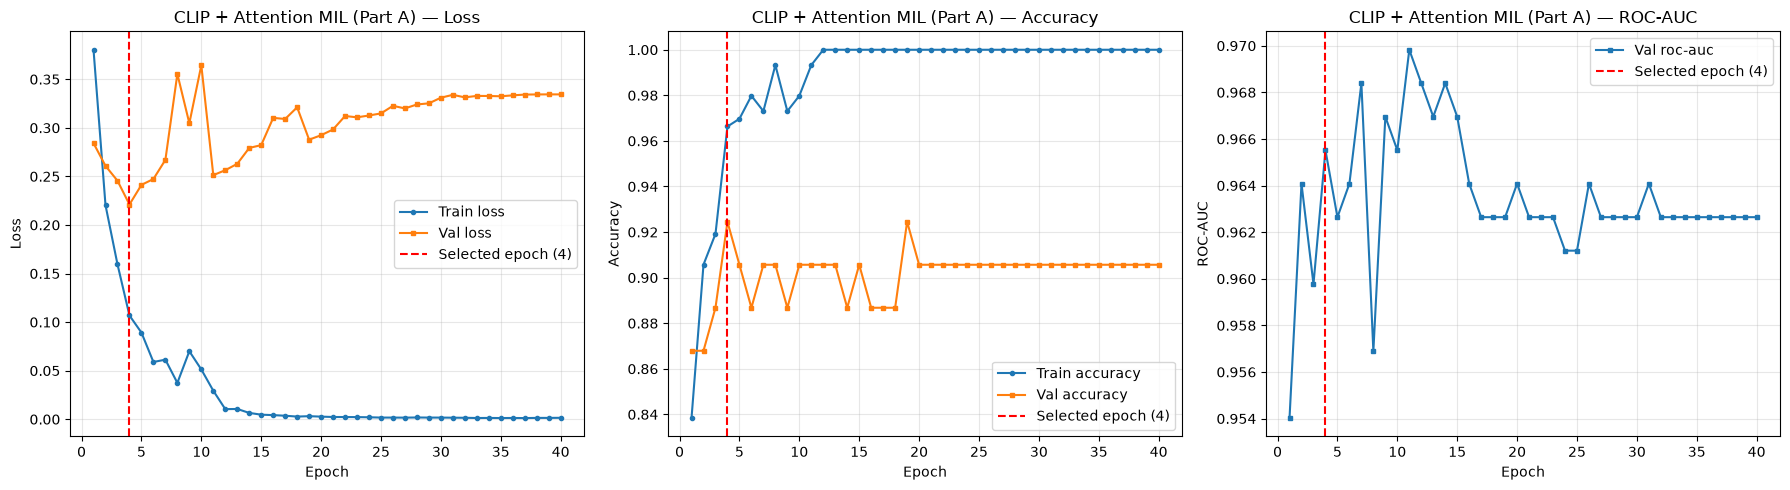

In [11]:
plot_history(hist_a, "CLIP + Attention MIL (Part A)", best_ep=best_ep_a, save_name="curves_part_a.png")

### Part A — accuracy, precision, recall, F1, ROC-AUC (VAL) + TEST predictions

===== CLIP + Attention MIL | VAL (53 videos, every frame) =====
       accuracy  precision  recall      f1  roc_auc
TRAIN    0.9832     0.9819  0.9879  0.9849   0.9978
VAL      0.9245     0.9630  0.8966  0.9286   0.9655
              precision    recall  f1-score   support

      NORMAL     0.8846    0.9583    0.9200        24
     ANOMALY     0.9630    0.8966    0.9286        29

    accuracy                         0.9245        53
   macro avg     0.9238    0.9274    0.9243        53
weighted avg     0.9275    0.9245    0.9247        53

Per-category accuracy:
                                  acc  videos
category                                     
Abuse                           1.000       2
Arrest                          1.000       1
Arson                           1.000       1
Assault                         1.000       2
Burglary                        0.333       3
Explosion                       1.000       2
Fighting                        1.000       1
RoadAccidents   

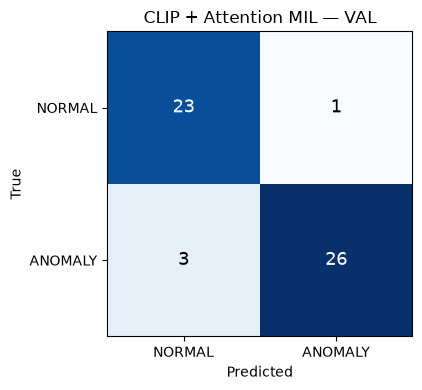

===== CLIP + Attention MIL | TEST (84 videos) -> ./runs_ucf_clipmil/test_predictions_clipmil.csv =====
prediction
NORMAL     48
ANOMALY    36


In [12]:
_, _, _, train_logits_a = evaluate(model_a, make_criterion(TRAIN_IDX), TRAIN_IDX)
_, _, _, val_logits_a = evaluate(model_a, make_criterion(TRAIN_IDX), VAL_IDX)
metrics[("CLIP + Attention MIL", "TRAIN")] = item_metrics(sigmoid(train_logits_a), train_items)
metrics[("CLIP + Attention MIL", "VAL")] = report(sigmoid(val_logits_a), val_items, "VAL", "CLIP + Attention MIL",
                                                  train_m=metrics[("CLIP + Attention MIL", "TRAIN")])
test_pred_a = predict_test([model_a], "CLIP + Attention MIL", "clipmil")

## 9. Anomaly timelines — where in the video does the model look?

For some VAL videos, plotted against time in the video:
- the attention weight of every clip (how much it decides the video, scaled so the largest is 1);
- the clip's own anomaly probability from the trained head;
- the clip's zero-shot anomaly probability (text prompts, no training).

The model was never told where the events are. It only received one label per video.

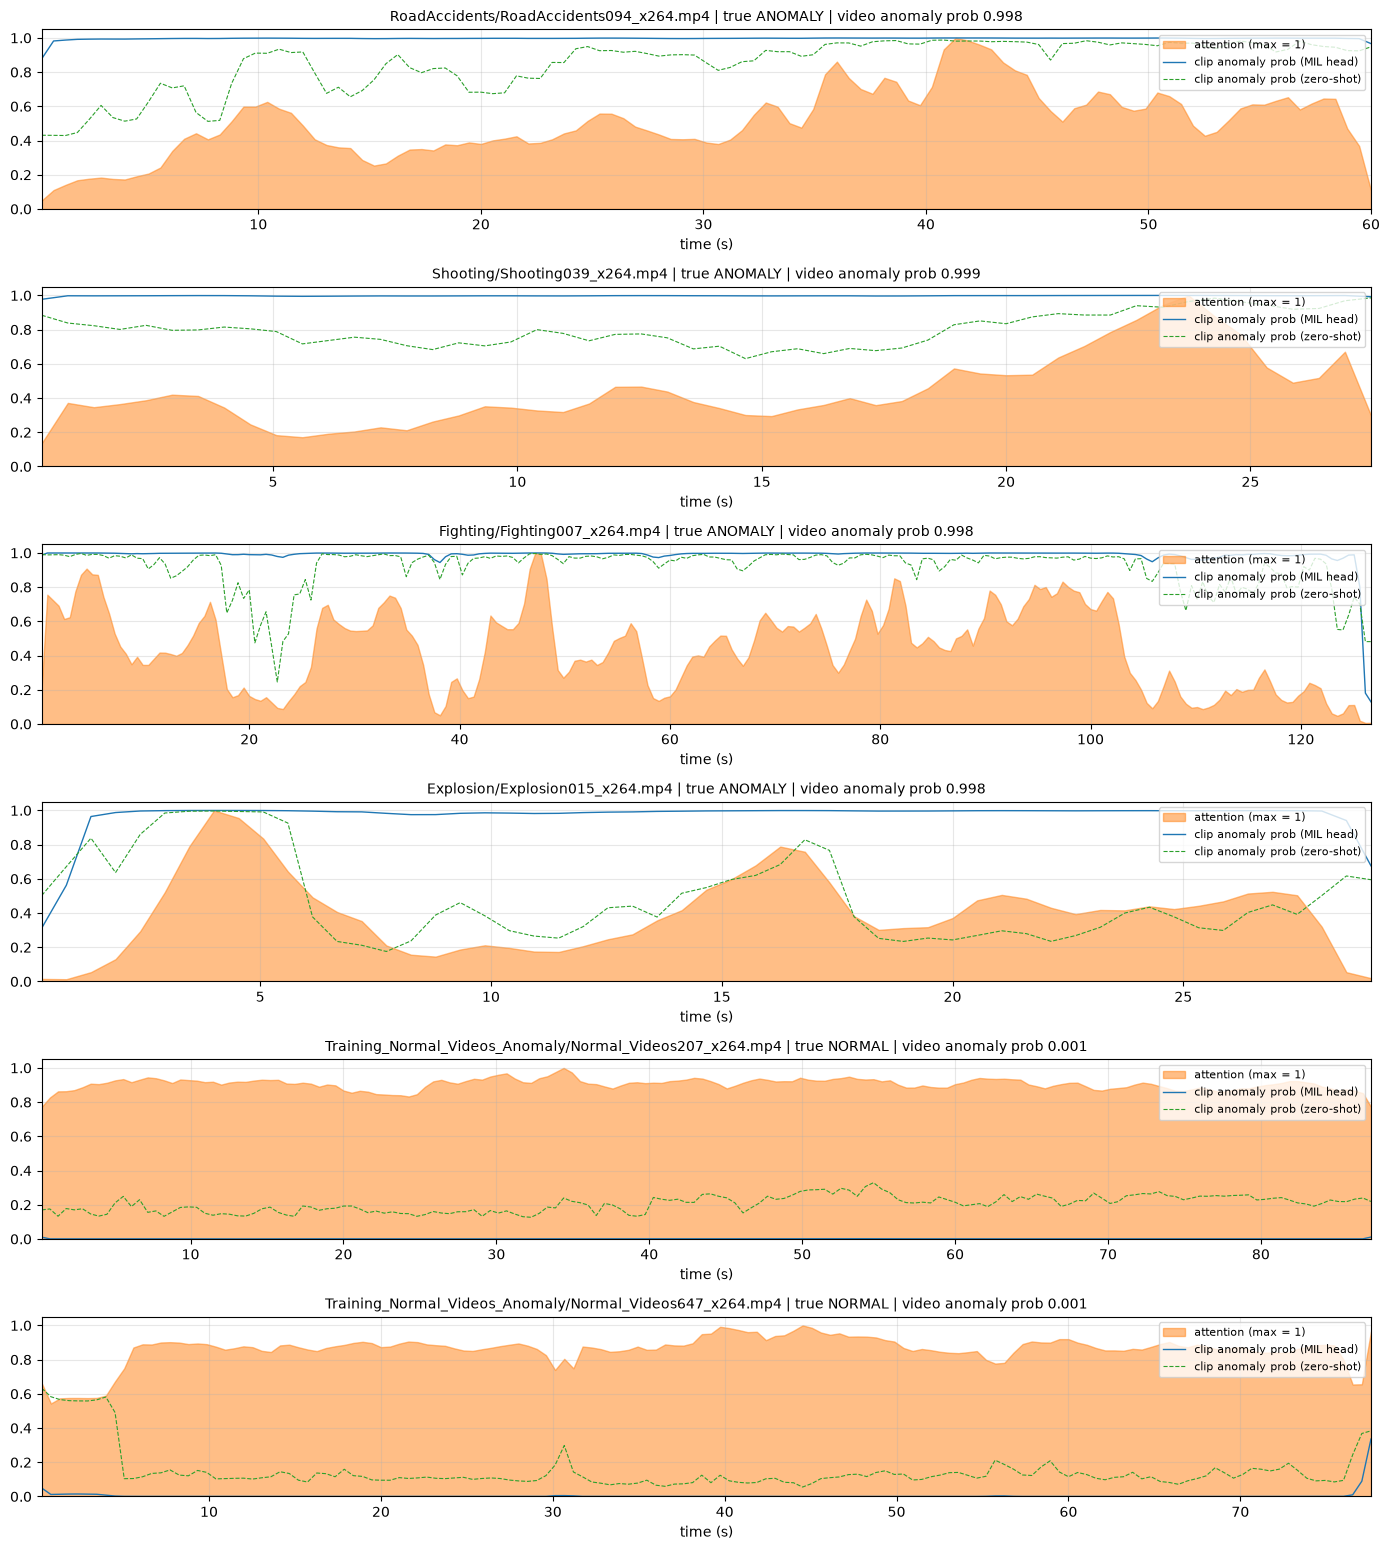

In [13]:
@torch.no_grad()
def plot_timelines(model, idx_list, save_name=None):
    fig, axes = plt.subplots(len(idx_list), 1, figsize=(14, 2.6 * len(idx_list)), squeeze=False)
    for ax, i in zip(axes[:, 0], idx_list):
        path, label = LAB_ITEMS[i]
        logit, attn, clip_logits = model(F_LAB["center"][i])
        attn = attn.cpu().numpy(); attn = attn / attn.max()
        t = (np.arange(len(attn)) * CLIP_LEN + CLIP_LEN / 2) / video_fps(path)
        unit = "min" if t[-1] > 600 else "s"
        t = t / 60 if unit == "min" else t
        ax.fill_between(t, 0, attn, color="tab:orange", alpha=0.5, label="attention (max = 1)")
        ax.plot(t, sigmoid(clip_logits.cpu().numpy()), color="tab:blue", lw=1, label="clip anomaly prob (MIL head)")
        ax.plot(t, zs_clip_probs(F_LAB["center"][i]).cpu().numpy(), color="tab:green", lw=0.8, ls="--",
                label="clip anomaly prob (zero-shot)")
        ax.set_ylim(0, 1.05); ax.set_xlim(t[0], t[-1]); ax.set_xlabel(f"time ({unit})")
        ax.set_title(f"{os.path.relpath(path, VIDEOS_DIR)} | true {CLASSES[label]} | "
                     f"video anomaly prob {sigmoid(logit.item()):.3f}", fontsize=10)
        ax.grid(alpha=0.3); ax.legend(loc="upper right", fontsize=8)
    plt.tight_layout()
    if save_name:
        plt.savefig(os.path.join(RUNS_DIR, save_name), dpi=120)
    plt.show()


# 4 VAL anomaly videos (highest predicted probability) + 2 VAL normal videos
order = VAL_IDX[np.argsort(-val_logits_a)]
show = [i for i in order if Y_LAB[i] == 1][:4] + [i for i in order[::-1] if Y_LAB[i] == 0][:2]
plot_timelines(model_a, show, save_name="timelines_val.png")

## 10. Part B — 5-fold cross-validation over all labelled videos (TRAIN + VAL = 350 videos)

Every labelled video is in the validation fold exactly once, so the **out-of-fold** accuracy is measured on 350 videos
instead of 53. Folds are stratified by category. Each fold trains for a fixed `EPOCHS` and uses the **last** epoch,
so no fold picks its checkpoint by looking at its own validation videos. This is the most honest number in the notebook.

The 5 fold models are also averaged into an ensemble for the TEST predictions.

In [14]:
cats = [category(p) for p, _ in LAB_ITEMS]
skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
with warnings.catch_warnings():
    warnings.filterwarnings("ignore", message="The least populated class")   # e.g. Arson has 4 videos < 5 folds
    folds = list(skf.split(np.zeros(len(LAB_ITEMS)), cats))

oof_logits = np.zeros(len(LAB_ITEMS))
fold_models, fold_hists, fold_rows, fold_train_rows = [], [], [], []
for k, (tr, va) in enumerate(folds, 1):
    t0 = time.time()
    model_k, hist_k, _ = fit(tr, va, select_best=False, seed=SEED + k, verbose=False)
    _, _, _, oof_logits[va] = evaluate(model_k, make_criterion(tr), va)
    _, _, _, tr_logits = evaluate(model_k, make_criterion(tr), tr)           # the fold's own training videos
    y_va, y_tr = Y_LAB[va].cpu().numpy().astype(int), Y_LAB[tr].cpu().numpy().astype(int)
    fold_rows.append(metric_dict(y_va, sigmoid(oof_logits[va])))
    fold_train_rows.append(metric_dict(y_tr, sigmoid(tr_logits)))
    fold_models.append(model_k); fold_hists.append(hist_k)
    torch.save(model_k.state_dict(), os.path.join(RUNS_DIR, f"cv_fold{k}.pt"))
    print(f"fold {k}/{N_FOLDS} | train {len(tr)} val {len(va)} | train acc {fold_train_rows[-1]['accuracy']:.4f} "
          f"auc {fold_train_rows[-1]['roc_auc']:.4f} | val acc {fold_rows[-1]['accuracy']:.4f} "
          f"auc {fold_rows[-1]['roc_auc']:.4f} | {time.time()-t0:.0f}s")

fold_df = pd.concat({"TRAIN": pd.DataFrame(fold_train_rows), "VAL": pd.DataFrame(fold_rows)}, axis=1)
fold_df.index = [f"fold {k}" for k in range(1, N_FOLDS + 1)]
fold_df.loc["mean"] = fold_df.mean(); fold_df.loc["std"] = fold_df.iloc[:N_FOLDS].std()
fold_df.round(4)

fold 1/5 | train 280 val 70 | train acc 1.0000 auc 1.0000 | val acc 0.9143 auc 0.9661 | 9s
fold 2/5 | train 280 val 70 | train acc 1.0000 auc 1.0000 | val acc 0.8857 auc 0.9239 | 8s
fold 3/5 | train 280 val 70 | train acc 1.0000 auc 1.0000 | val acc 0.8857 auc 0.9578 | 9s
fold 4/5 | train 280 val 70 | train acc 1.0000 auc 1.0000 | val acc 0.8857 auc 0.9653 | 9s
fold 5/5 | train 280 val 70 | train acc 1.0000 auc 1.0000 | val acc 0.9143 auc 0.9770 | 8s


TRAIN                                    VAL                    \
       accuracy precision recall   f1 roc_auc accuracy precision  recall   
fold 1      1.0       1.0    1.0  1.0     1.0   0.9143    0.9459  0.8974   
fold 2      1.0       1.0    1.0  1.0     1.0   0.8857    0.8974  0.8974   
fold 3      1.0       1.0    1.0  1.0     1.0   0.8857    0.8780  0.9231   
fold 4      1.0       1.0    1.0  1.0     1.0   0.8857    0.8780  0.9231   
fold 5      1.0       1.0    1.0  1.0     1.0   0.9143    0.9000  0.9474   
mean        1.0       1.0    1.0  1.0     1.0   0.8971    0.8999  0.9177   
std         0.0       0.0    0.0  0.0     0.0   0.0156    0.0278  0.0210   

                        
            f1 roc_auc  
fold 1  0.9211  0.9661  
fold 2  0.8974  0.9239  
fold 3  0.9000  0.9578  
fold 4  0.9000  0.9653  
fold 5  0.9231  0.9770  
mean    0.9083  0.9580  
std     0.0126  0.0203

### Part B — curves averaged over the 5 folds (shaded = ± 1 std)

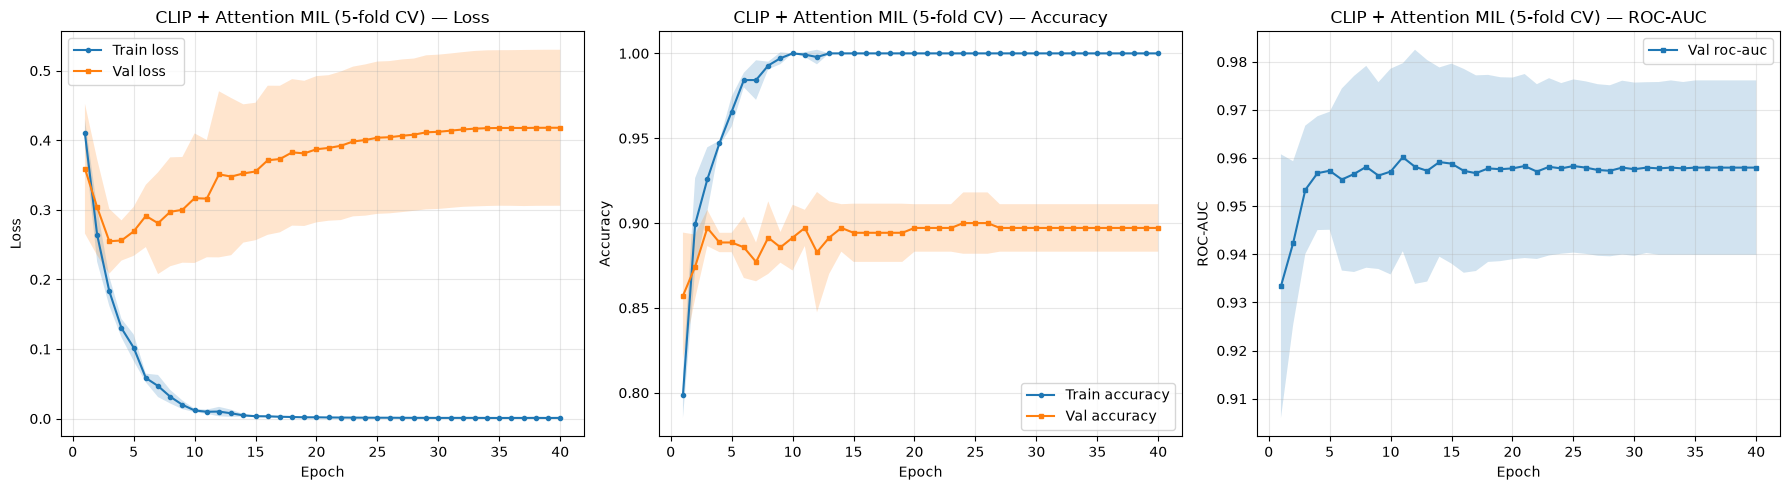

In [15]:
plot_history({k: [h[k] for h in fold_hists] for k in fold_hists[0]}, f"CLIP + Attention MIL ({N_FOLDS}-fold CV)",
             save_name="curves_cv.png")

### Part B — out-of-fold metrics on all 350 labelled videos + TEST predictions (5-fold ensemble)

===== CLIP + Attention MIL 5-fold CV | TRAIN+VAL (350 videos) (350 videos, every frame) =====
                            accuracy  precision  recall      f1  roc_auc
TRAIN (in-fold, fold mean)    1.0000      1.000  1.0000  1.0000   1.0000
TRAIN+VAL (350 videos)         0.8971      0.899  0.9175  0.9082   0.9585
              precision    recall  f1-score   support

      NORMAL     0.8947    0.8718    0.8831       156
     ANOMALY     0.8990    0.9175    0.9082       194

    accuracy                         0.8971       350
   macro avg     0.8969    0.8947    0.8956       350
weighted avg     0.8971    0.8971    0.8970       350

Per-category accuracy:
                                  acc  videos
category                                     
Abuse                           1.000      13
Arrest                          0.900      10
Arson                           1.000       4
Assault                         1.000      16
Burglary                        0.810      21
Explosion     

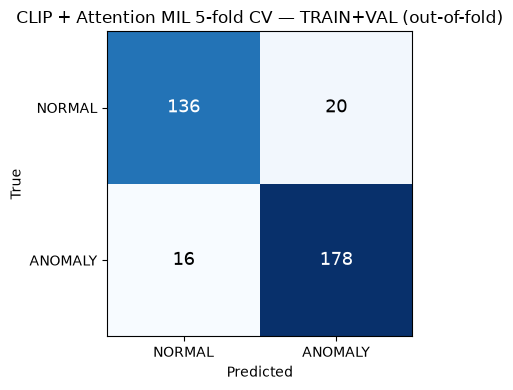

===== CLIP + Attention MIL 5-fold ensemble | TEST (84 videos) -> ./runs_ucf_clipmil/test_predictions_clipmil_cv_ensemble.csv =====
prediction
NORMAL     50
ANOMALY    34


In [16]:
cv_stage = f"CLIP + Attention MIL, {N_FOLDS}-fold CV"
metrics[(cv_stage, "TRAIN (in-fold, fold mean)")] = pd.DataFrame(fold_train_rows).mean().to_dict()
metrics[(cv_stage, "TRAIN+VAL (350 videos)")] = report(
    sigmoid(oof_logits), LAB_ITEMS, "TRAIN+VAL (350 videos)", f"CLIP + Attention MIL {N_FOLDS}-fold CV",
    train_m=metrics[(cv_stage, "TRAIN (in-fold, fold mean)")], train_name="TRAIN (in-fold, fold mean)")
test_pred_cv = predict_test(fold_models, f"CLIP + Attention MIL {N_FOLDS}-fold ensemble", "clipmil_cv_ensemble")

## 11. Comparison with notebook 02 (R(2+1)D, mean pooling over the whole video)

The VAL rows use the same 53 videos as notebook 02. The cross-validation row uses all 350 labelled videos, so it is not
directly comparable to the VAL rows, but it is the most reliable estimate of accuracy. The notebook 02 rows are read from
`runs_ucf_fullvideo/metrics_summary.csv` and are skipped if that file does not exist.

In [17]:
summary = pd.DataFrame({k: v for k, v in metrics.items() if v is not None}).T
summary.index.names = ["stage", "split"]
summary.to_csv(os.path.join(RUNS_DIR, "metrics_summary.csv"))

prev_tables = []
for tag, run_dir in PREV_RUNS.items():
    prev_csv = os.path.join(run_dir, "metrics_summary.csv")
    if os.path.exists(prev_csv):
        prev = pd.read_csv(prev_csv).set_index(["stage", "split"])
        prev.index = pd.MultiIndex.from_tuples([(f"{tag}: {s}", sp) for s, sp in prev.index], names=["stage", "split"])
        prev_tables.append(prev)
pd.concat(prev_tables + [summary]).round(4)

accuracy  \
stage                                        split                                  
02 R(2+1)D mean pooling: Feature extraction  VAL                           0.8113   
02 R(2+1)D mean pooling: Fine-tuned (layer4) VAL                           0.8679   
CLIP zero-shot                               TRAIN                         0.7643   
                                             VAL                           0.8302   
CLIP + Attention MIL                         TRAIN                         0.9832   
                                             VAL                           0.9245   
CLIP + Attention MIL, 5-fold CV              TRAIN (in-fold, fold mean)    1.0000   
                                             TRAIN+VAL (350 videos)         0.8971   

                                                                         precision  \
stage                                        split                                   
02 R(2+1)D mean pooling: Feature extraction  VAL                            0.7879   
02 R(2+1)D mean pooling: Fine-tuned (layer4) VAL                            0.8929   
CLIP zero-shot                               TRAIN                          0.7684   
                                             VAL                            0.8571   
CLIP + Attention MIL                         TRAIN                          0.9819   
                                             VAL                            0.9630   
CLIP + Attention MIL, 5-fold CV              TRAIN (in-fold, fold mean)     1.0000   
                                             TRAIN+VAL (350 videos)        0.8990   

                                                                         recall  \
stage                                        split                                
02 R(2+1)D mean pooling: Feature extraction  VAL                         0.8966   
02 R(2+1)D mean pooling: Fine-tuned (layer4) VAL                         0.8621   
CLIP zero-shot                               TRAIN                       0.8242   
                                             VAL                         0.8276   
CLIP + Attention MIL                         TRAIN                       0.9879   
                                             VAL                         0.8966   
CLIP + Attention MIL, 5-fold CV              TRAIN (in-fold, fold mean)  1.0000   
                                             TRAIN+VAL (350 videos)     0.9175   

                                                                             f1  \
stage                                        split                                
02 R(2+1)D mean pooling: Feature extraction  VAL                         0.8387   
02 R(2+1)D mean pooling: Fine-tuned (layer4) VAL                         0.8772   
CLIP zero-shot                               TRAIN                       0.7953   
                                             VAL                         0.8421   
CLIP + Attention MIL                         TRAIN                       0.9849   
                                             VAL                         0.9286   
CLIP + Attention MIL, 5-fold CV              TRAIN (in-fold, fold mean)  1.0000   
                                             TRAIN+VAL (350 videos)     0.9082   

                                                                         roc_auc  
stage                                        split                                
02 R(2+1)D mean pooling: Feature extraction  VAL                          0.8405  
02 R(2+1)D mean pooling: Fine-tuned (layer4) VAL                          0.9382  
CLIP zero-shot                               TRAIN                        0.8211  
                                             VAL                          0.8261  
CLIP + Attention MIL                         TRAIN                        0.9978  
                                             VAL                          0.9655  
CLIP + Attention MIL, 5-fold CV      